# Step 0 - Download the raw Lichess file and profile it

**What this notebook does (in order)**
1. **Download** one pinned monthly Lichess file (resumable: if the connection drops, just run the cell again).
2. **Verify and record** it: exact byte size, SHA-256, and a `download_manifest.json`.
3. **Profile** the whole file in one streaming pass (no sampling): what is in it, before any filtering.
4. **Plot** everything (figures are saved as PNG for the thesis) and save every table as CSV.

**Reproducible because:** the month, URL, size, SHA-256, package versions and a hash of all result tables are written to the manifests.
Same file + same notebook = the same `results_sha256`.

**Time and space:** a recent month is roughly 30 GB to download and the profiling pass takes roughly 1 hour (30-90 minutes depending on the computer).
The pass saves checkpoints, so you can stop it (Ctrl+C / close VS Code) and run the same cell again to continue.
Try `MAX_GAMES = 1_000_000` first for a quick test.

Needs (once): `pip install -r requirements.txt`. Open the notebook from the project folder.

In [6]:
import io, os, re, sys, json, time, pickle, hashlib, platform, datetime
from collections import Counter
from importlib import metadata
from pathlib import Path
import subprocess
import numpy as np
import pandas as pd
import requests, zstandard
import matplotlib.pyplot as plt
import config

# ===================== PARAMETERS - scientific settings come from config.py =====================
MONTH = config.MONTH
BASE_URL = config.BASE_URL
LICHESS_FILE = config.LICHESS_FILE
MAX_RATING_GAP = config.MAX_RATING_GAP
MIN_EST_SECONDS = config.MIN_EST_SECONDS
MAX_GAMES = None          # None = whole file. Use e.g. 1_000_000 for a quick test run
TAG_SAMPLE_GAMES = 2_000_000   # header-tag fill rates are counted on the first N games only (the tag set is stable)
CHECKPOINT_EVERY = 5_000_000   # games between checkpoints
RECHECK_HASH = False      # False: reuse the saved SHA-256 if the file size is unchanged
RAW_OVERRIDE = None       # path to an existing local file (skips the download); None = normal
# ===============================================================================

FILE = LICHESS_FILE
URL = BASE_URL + FILE
PROJECT = Path.cwd()
RAW = Path(RAW_OVERRIDE) if RAW_OVERRIDE else PROJECT / "data" / "raw" / FILE
OUT = PROJECT / "outputs" / "step0_dataset" / MONTH
TABLES, FIGS = OUT / "tables", OUT / "figures"
for d in (RAW.parent, TABLES, FIGS):
    d.mkdir(parents=True, exist_ok=True)
CODE_VERSION = "step0-v1"      # bump if you change the profiling logic (invalidates old checkpoints)
print("month:", MONTH, "| file:", FILE, "\nraw file path:", RAW, "\noutputs:", OUT)

month: 2026-10 | file: lichess_db_standard_rated_2026-10.pgn.zst 
raw file path: d:\files for Germany\srh\GitHub files\chess-explanations-thesis\data\raw\lichess_db_standard_rated_2026-10.pgn.zst 
outputs: d:\files for Germany\srh\GitHub files\chess-explanations-thesis\outputs\step0_dataset\2026-10


## 1. Download (resumable)
Streams to `<file>.part` and renames it when the size matches what the server announced.
If anything goes wrong, **run this cell again** and it continues from where it stopped.

In [7]:
import sys, numpy
print(sys.executable, numpy.__version__)

d:\files for Germany\srh\GitHub files\chess-explanations-thesis\.venv\Scripts\python.exe 2.4.3


In [8]:
def remote_size(url):
    r = requests.head(url, allow_redirects=True, timeout=60); r.raise_for_status()
    return int(r.headers["Content-Length"])

def download(url, dest, expected, chunk=1 << 22, tick=15):
    part = dest.with_name(dest.name + ".part")
    if dest.exists():                                   # an incomplete file with the final name: continue it
        if dest.stat().st_size > expected:
            raise RuntimeError(f"{dest} is larger than the server file; delete it and run again")
        dest.replace(part)
    have = part.stat().st_size if part.exists() else 0
    if have > expected:
        part.unlink(); have = 0
    if have < expected:
        headers = {"Range": f"bytes={have}-"} if have else {}
        with requests.get(url, headers=headers, stream=True, timeout=60) as r:
            r.raise_for_status()
            mode = "ab" if (have and r.status_code == 206) else "wb"
            done = have if mode == "ab" else 0
            print(f"{'Resuming at' if mode == 'ab' else 'Starting at'} {done/1e9:.2f} GB of {expected/1e9:.2f} GB")
            t0 = last = time.time(); start = done
            with open(part, mode) as f:
                for blk in r.iter_content(chunk):
                    f.write(blk); done += len(blk)
                    if time.time() - last > tick:
                        last = time.time(); rate = (done - start) / (last - t0) / 1e6
                        print(f"  {done/expected:6.1%}  {done/1e9:6.2f} GB  {rate:5.1f} MB/s", flush=True)
    if part.stat().st_size != expected:
        raise RuntimeError(f"incomplete: {part.stat().st_size:,} of {expected:,} bytes. Run this cell again to resume.")
    part.replace(dest)

if RAW_OVERRIDE:
    expected = RAW.stat().st_size
    print("Using local file (no download):", RAW)
else:
    expected = remote_size(URL)
    if RAW.exists() and RAW.stat().st_size == expected:
        print(f"Already downloaded and complete: {RAW.name} ({expected/1e9:.2f} GB)")
    else:
        download(URL, RAW, expected)
        print("Download complete:", RAW)

Already downloaded and complete: lichess_db_standard_rated_2026-10.pgn.zst (30.98 GB)


## 2. Verify and record (reproducibility anchor)
Records the exact size and SHA-256 of the file. If Lichess publishes a checksum list we compare against it (best effort; not every server provides one).

In [9]:
def sha256_file(path, chunk=1 << 24):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while blk := f.read(chunk):
            h.update(blk)
    return h.hexdigest()

def pkg_versions():
    out = {}
    for p in ["requests", "zstandard", "numpy", "pandas", "matplotlib"]:
        try: out[p] = metadata.version(p)
        except metadata.PackageNotFoundError: pass
    return out

def git_commit():
    try:
        return subprocess.run(["git", "-C", str(PROJECT), "rev-parse", "HEAD"],
                              check=True, capture_output=True, text=True).stdout.strip()
    except (subprocess.CalledProcessError, FileNotFoundError):
        return None

CONFIG_SNAPSHOT = config.config_snapshot()
GIT_COMMIT = git_commit()

MAN = OUT / "download_manifest.json"
size = RAW.stat().st_size
old = json.loads(MAN.read_text()) if MAN.exists() else {}
if old.get("bytes") == size and old.get("sha256") and not RECHECK_HASH:
    sha = old["sha256"]; print("Reusing saved SHA-256 (size unchanged).")
else:
    print("Computing SHA-256 (about 1-3 minutes for 30 GB)...")
    sha = sha256_file(RAW)

official = None
try:
    r = requests.get(BASE_URL + "sha256sums.txt", timeout=30)
    if r.ok:
        for line in r.text.splitlines():
            parts = line.split()
            if len(parts) >= 2 and parts[-1].lstrip("*") == FILE:
                official = parts[0]
except requests.RequestException:
    pass

manifest = dict(step="step0_download", month=MONTH, file=FILE, url=URL, bytes=size, sha256=sha,
                official_sha256=official, matches_official=(None if official is None else official == sha),
                timestamp_utc=datetime.datetime.now(datetime.timezone.utc).isoformat(timespec="seconds"),
                python=sys.version.split()[0], platform=platform.platform(), packages=pkg_versions(),
                config=CONFIG_SNAPSHOT, git_commit=GIT_COMMIT)
MAN.write_text(json.dumps(manifest, indent=2))
print(f"{FILE}\n  size   : {size:,} bytes ({size/1e9:.2f} GB)\n  sha256 : {sha}")
print("  official checksum:", "not available from the server" if official is None else ("MATCH" if official == sha else "MISMATCH - re-download!"))

Reusing saved SHA-256 (size unchanged).
lichess_db_standard_rated_2026-10.pgn.zst
  size   : 30,982,323,881 bytes (30.98 GB)
  sha256 : 043906ebfade1bfeb7c00087590fac505370936c028525e4722e2dbd4986ae86
  official checksum: MATCH


## 3. Profile the whole file (one streaming pass, resumable)
For every game we read the header tags and the move text and update counters. Nothing is sampled except the header-tag fill rates (first `TAG_SAMPLE_GAMES` games).
Stop any time and rerun this cell: it resumes from the last checkpoint and gives the identical result.

In [10]:
THRESH = [1800, 2000, 2200, 2400, 2500, config.ELO_MIN, 2700]
WANT = {b"WhiteElo", b"BlackElo", b"TimeControl", b"Termination", b"Result", b"WhiteTitle", b"BlackTitle", b"ECO", b"UTCDate", b"Event"}
SPEED_KEYS = (b"UltraBullet", b"Bullet", b"Blitz", b"Rapid", b"Classical", b"Correspondence")
MOVE_NO = re.compile(rb"(?<![\d.])(\d+)\.(?!\d)")      # '12.' or '12...' but not the '0.' in '[%eval 0.17]'
TC = re.compile(rb"(\d+)\+(\d+)")

def speed_of(event):
    for k in SPEED_KEYS:
        if k in event: return k.decode()
    return "Other"

def est_seconds(tc):
    m = TC.fullmatch(tc); return int(m[1]) + 40 * int(m[2]) if m else None

def to_elo(b):
    try:
        v = int(b); return v if 0 < v < 4000 else None
    except (TypeError, ValueError):
        return None

def full_moves(mt):
    m = MOVE_NO.findall(mt[-400:]); return int(m[-1]) if m else 0

def new_state():
    keys = ["tags", "result", "term", "speed", "tc", "w", "b", "mn", "gap", "titles", "bot", "eco", "day", "moves",
            "moves_speed", "eval_speed", "clk_speed", "eval_band", "cohort", "quality"]
    S = {k: Counter() for k in keys}; S["n"] = 0; return S

def process(h, mt, S):
    S["n"] += 1
    S["result"][h.get(b"Result", b"?")] += 1
    S["term"][h.get(b"Termination", b"?")] += 1
    speed = speed_of(h.get(b"Event", b"")); S["speed"][speed] += 1
    tc = h.get(b"TimeControl", b"?"); S["tc"][tc] += 1
    est = est_seconds(tc)
    if est is None: S["quality"]["no_clock_time_control"] += 1
    w, b = to_elo(h.get(b"WhiteElo")), to_elo(h.get(b"BlackElo"))
    wt, bt = h.get(b"WhiteTitle"), h.get(b"BlackTitle")
    if wt: S["titles"][wt] += 1
    if bt: S["titles"][bt] += 1
    bot = wt == b"BOT" or bt == b"BOT"
    S["bot"][(speed, int(bot))] += 1
    S["eco"][h.get(b"ECO", b"?")] += 1
    S["day"][h.get(b"UTCDate", b"?")] += 1
    has_eval, has_clk = b"[%eval" in mt, b"[%clk" in mt
    S["eval_speed"][(speed, int(has_eval))] += 1; S["clk_speed"][(speed, int(has_clk))] += 1
    mv = full_moves(mt); S["moves"][min(mv, 300)] += 1; S["moves_speed"][(speed, min(mv, 300))] += 1
    if mv == 0: S["quality"]["no_moves"] += 1
    if h.get(b"Result") == b"*": S["quality"]["unfinished_result_star"] += 1
    if w is None or b is None:
        S["quality"]["missing_or_invalid_elo"] += 1; S["eval_band"][(-1, int(has_eval))] += 1
        return
    mn, gap = min(w, b), abs(w - b)
    S["w"][w] += 1; S["b"][b] += 1; S["mn"][mn] += 1; S["gap"][gap] += 1
    S["eval_band"][(mn // 100 * 100, int(has_eval))] += 1
    if mn >= THRESH[0]:
        tier = max(i for i, t in enumerate(THRESH) if mn >= t)
        S["cohort"][(tier, int(gap <= MAX_RATING_GAP), int(est is not None and est >= MIN_EST_SECONDS),
                     int(h.get(b"Termination") == b"Normal"), int(not bot), int(has_eval))] += 1

def profile(path, max_games, ckpt_path):
    fp = dict(month=MONTH, size=path.stat().st_size, max_games=max_games, tag_sample=TAG_SAMPLE_GAMES,
              code=CODE_VERSION, max_rating_gap=MAX_RATING_GAP, min_est_seconds=MIN_EST_SECONDS,
              config=CONFIG_SNAPSHOT, git_commit=GIT_COMMIT)
    S, skip = new_state(), 0
    if ckpt_path.exists():
        ck = pickle.load(open(ckpt_path, "rb"))
        if ck["fingerprint"] == fp:
            S, skip = ck["state"], ck["state"]["n"]; print(f"Resuming from checkpoint: {skip:,} games already done")
        else:
            print("Checkpoint belongs to different settings - starting fresh")
    total_bytes = path.stat().st_size; t0 = last = time.time(); partial = False
    with open(path, "rb") as raw, zstandard.ZstdDecompressor(max_window_size=2**31).stream_reader(raw) as rd:
        f = io.BufferedReader(rd, buffer_size=1 << 22)
        hdr, seen = {}, 0
        for line in f:
            if line[:1] == b"[":
                if seen >= skip:
                    sp = line.find(b" "); tag = line[1:sp]
                    if S["n"] < TAG_SAMPLE_GAMES: S["tags"][tag] += 1
                    if tag in WANT: hdr[tag] = line[sp + 2: line.rfind(b'"')]
            elif line.strip():
                seen += 1
                if seen > skip:
                    process(hdr, line, S)
                    n = S["n"]
                    if n % 100_000 == 0 and time.time() - last > 20:
                        last = time.time(); frac = raw.tell() / total_bytes
                        el = last - t0; print(f"  {n:>12,} games  {frac:6.1%} of file  elapsed {el/60:5.1f} min  ETA {el/max(frac,1e-9)*(1-frac)/60:5.1f} min", flush=True)
                    if n % CHECKPOINT_EVERY == 0:
                        pickle.dump({"fingerprint": fp, "state": S}, open(str(ckpt_path) + ".tmp", "wb")); os.replace(str(ckpt_path) + ".tmp", ckpt_path)
                    if max_games and n >= max_games:
                        partial = True; break
                hdr = {}
    S["partial"] = partial; S["fingerprint"] = fp
    return S

STATE_FILE = OUT / "profile_state.pkl"
CKPT = OUT / "checkpoint.pkl"
fp_now = dict(month=MONTH, size=RAW.stat().st_size, max_games=MAX_GAMES, tag_sample=TAG_SAMPLE_GAMES,
          code=CODE_VERSION, max_rating_gap=MAX_RATING_GAP, min_est_seconds=MIN_EST_SECONDS,
          config=CONFIG_SNAPSHOT, git_commit=GIT_COMMIT)
done_before = STATE_FILE.exists() and pickle.load(open(STATE_FILE, "rb")).get("fingerprint") == fp_now
if done_before:
    print("Profile already finished for these settings - loading it (delete profile_state.pkl to recompute).")
    S = pickle.load(open(STATE_FILE, "rb"))
else:
    t_start = time.time()
    S = profile(RAW, MAX_GAMES, CKPT)
    pickle.dump(S, open(STATE_FILE, "wb"))
    if CKPT.exists(): CKPT.unlink()
    print(f"Done: {S['n']:,} games in {(time.time()-t_start)/60:.1f} min" + ("  (PARTIAL: MAX_GAMES reached)" if S["partial"] else ""))

       600,000 games    0.6% of file  elapsed   0.4 min  ETA  57.2 min
     1,200,000 games    1.3% of file  elapsed   0.8 min  ETA  61.0 min
     1,500,000 games    1.6% of file  elapsed   1.2 min  ETA  73.6 min
     1,800,000 games    1.9% of file  elapsed   1.5 min  ETA  79.5 min
     2,100,000 games    2.2% of file  elapsed   1.9 min  ETA  83.0 min
     2,400,000 games    2.5% of file  elapsed   2.2 min  ETA  85.1 min
     2,700,000 games    2.9% of file  elapsed   2.6 min  ETA  88.9 min
     3,000,000 games    3.2% of file  elapsed   3.0 min  ETA  91.6 min
     3,400,000 games    3.6% of file  elapsed   3.4 min  ETA  92.4 min
     3,800,000 games    4.0% of file  elapsed   3.9 min  ETA  92.4 min
     4,100,000 games    4.3% of file  elapsed   4.2 min  ETA  92.8 min
     4,400,000 games    4.6% of file  elapsed   4.5 min  ETA  93.4 min
     4,800,000 games    5.1% of file  elapsed   5.0 min  ETA  93.2 min
     5,100,000 games    5.4% of file  elapsed   5.3 min  ETA  93.4 min
     5

## 4. Save all tables (CSV) + results hash

In [11]:
dec = lambda b: b.decode("utf-8", "replace") if isinstance(b, bytes) else str(b)
def save_csv(name, df): df.to_csv(TABLES / f"{name}.csv", index=False)
def counter_df(c, col, top=None):
    items = c.most_common(top) if top else sorted(c.items(), key=lambda kv: kv[0])
    df = pd.DataFrame([(dec(k), v) for k, v in items], columns=[col, "games"]); df["share"] = df.games / S["n"]; return df

save_csv("results", counter_df(S["result"], "result")); save_csv("terminations", counter_df(S["term"], "termination"))
save_csv("speed", counter_df(S["speed"], "speed")); save_csv("time_controls_top40", counter_df(S["tc"], "time_control", 40))
save_csv("titles", counter_df(S["titles"], "title")); save_csv("eco_top30", counter_df(S["eco"], "eco", 30))
save_csv("games_per_day", counter_df(S["day"], "date"))
tf = pd.DataFrame([(dec(k), v) for k, v in S["tags"].most_common()], columns=["tag", "games_with_tag"])
tf["share"] = tf.games_with_tag / min(S["n"], TAG_SAMPLE_GAMES); save_csv("tag_fill_rates", tf)
elo = pd.DataFrame({"elo": sorted(set(S["w"]) | set(S["b"]) | set(S["mn"]))})
for k, col in (("w", "white"), ("b", "black"), ("mn", "min_of_both")): elo[col] = elo.elo.map(S[k]).fillna(0).astype(int)
save_csv("elo_exact", elo)
save_csv("rating_gap_exact", pd.DataFrame(sorted(S["gap"].items()), columns=["gap", "games"]))
save_csv("full_moves", pd.DataFrame(sorted(S["moves"].items()), columns=["full_moves", "games"]))
save_csv("full_moves_by_speed", pd.DataFrame([(a, m, v) for (a, m), v in sorted(S["moves_speed"].items())], columns=["speed", "full_moves", "games"]))
for key, name in (("eval_speed", "eval_by_speed"), ("clk_speed", "clock_by_speed")):
    save_csv(name, pd.DataFrame([(a, h, v) for (a, h), v in sorted(S[key].items())], columns=["speed", "has", "games"]))
save_csv("bots_by_speed", pd.DataFrame([(a, h, v) for (a, h), v in sorted(S["bot"].items())], columns=["speed", "has_bot", "games"]))
save_csv("eval_by_min_elo_band", pd.DataFrame([(a, h, v) for (a, h), v in sorted(S["eval_band"].items())], columns=["min_elo_band", "has_eval", "games"]))
save_csv("cohort_counts", pd.DataFrame([(*k, v) for k, v in sorted(S["cohort"].items())], columns=["tier_idx", "gap_ok", "rapid_plus", "normal", "no_bot", "has_eval", "games"]))
overview = dict(month=MONTH, games=S["n"], partial=S["partial"], tag_sample_games=min(S["n"], TAG_SAMPLE_GAMES), data_quality=dict(S["quality"]))
(TABLES / "overview.json").write_text(json.dumps(overview, indent=2))

h = hashlib.sha256()
for p in sorted(TABLES.glob("*.csv")) + [TABLES / "overview.json"]:
    h.update(p.name.encode()); h.update(p.read_bytes())
results_sha = h.hexdigest()
pm = dict(step="step0_profile", month=MONTH, file_sha256=manifest["sha256"], games=S["n"], partial=S["partial"], code_version=CODE_VERSION,
          results_sha256=results_sha, timestamp_utc=datetime.datetime.now(datetime.timezone.utc).isoformat(timespec="seconds"),
          python=sys.version.split()[0], platform=platform.platform(), packages=pkg_versions(),
          parameters=dict(MAX_GAMES=MAX_GAMES, TAG_SAMPLE_GAMES=TAG_SAMPLE_GAMES,
                          MAX_RATING_GAP=MAX_RATING_GAP, MIN_EST_SECONDS=MIN_EST_SECONDS),
          config=CONFIG_SNAPSHOT, git_commit=GIT_COMMIT)
(OUT / "profile_manifest.json").write_text(json.dumps(pm, indent=2))
print("tables saved in", TABLES, "\nresults_sha256 =", results_sha)

tables saved in d:\files for Germany\srh\GitHub files\chess-explanations-thesis\outputs\step0_dataset\2026-10\tables 
results_sha256 = 4fce373d463737f45fb9d5653d240787518d8dc429c4337a4b97ee71b48bd643


## 5. Key facts
The numbers I will quote in the thesis. Percentiles are exact (computed from per-rating counts) over all player-rating observations (White and Black).

In [12]:
T = lambda n: pd.read_csv(TABLES / f"{n}.csv")
N = S["n"]
speed, ev, clk, bots = T("speed"), T("eval_by_speed"), T("clock_by_speed"), T("bots_by_speed")
elo = T("elo_exact"); allr = (elo.white + elo.black).values; cum = np.cumsum(allr) / allr.sum()
pct = {p: int(elo.elo.values[np.searchsorted(cum, p / 100)]) for p in (50, 75, 90, 95, 99, 99.9)}
mnc = np.cumsum(elo.min_of_both.values[::-1])[::-1]
share_min = lambda t: elo.min_of_both[elo.elo >= t].sum() / elo.min_of_both.sum()
rapid_plus = speed[speed.speed.isin(["Rapid", "Classical"])].games.sum()
facts = {
    "games in file": f"{N:,}", "compressed size": f"{manifest['bytes']/1e9:.2f} GB",
    "rapid or classical (Event tag)": f"{rapid_plus/N:.2%}",
    "games with Lichess evals": f"{ev[ev.has == 1].games.sum()/N:.2%}",
    "games with clock times": f"{clk[clk.has == 1].games.sum()/N:.2%}",
    "games with a bot account": f"{bots[bots.has_bot == 1].games.sum()/N:.2%}",
    "median full moves": int(T('full_moves').pipe(lambda d: d.full_moves.values[np.searchsorted(np.cumsum(d.games) / d.games.sum(), 0.5)])),
    "rating percentiles (all players)": ", ".join(f"p{p}={v}" for p, v in pct.items()),
    "games with BOTH players >= 2400 / 2500 / 2600": " / ".join(f"{share_min(t):.2%}" for t in (2400, 2500, 2600)),
}
display(pd.Series(facts, name="value").to_frame()); print("data quality:", dict(S["quality"]))

,value
games in file,"95,395,628"
compressed size,30.98 GB
rapid or classical (Event tag),18.05%
games with Lichess evals,9.86%
games with clock times,99.48%
games with a bot account,0.52%
median full moves,31
rating percentiles (all players),"p50=1645, p75=1912, p90=2138, p95=2277, p99=25..."
games with BOTH players >= 2400 / 2500 / 2600,1.94% / 1.05% / 0.56%


data quality: {'no_moves': 407406, 'no_clock_time_control': 99689, 'unfinished_result_star': 476436}


## 6. Plots
Every figure is saved in `outputs/step0_dataset/<month>/figures/`.

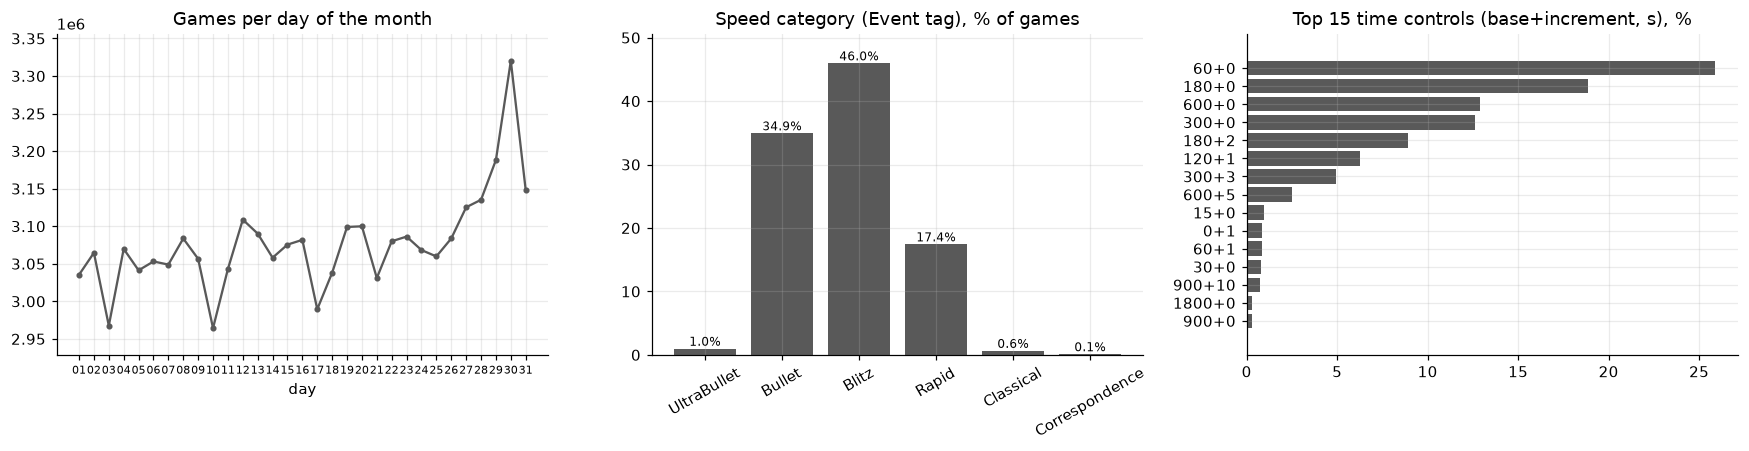

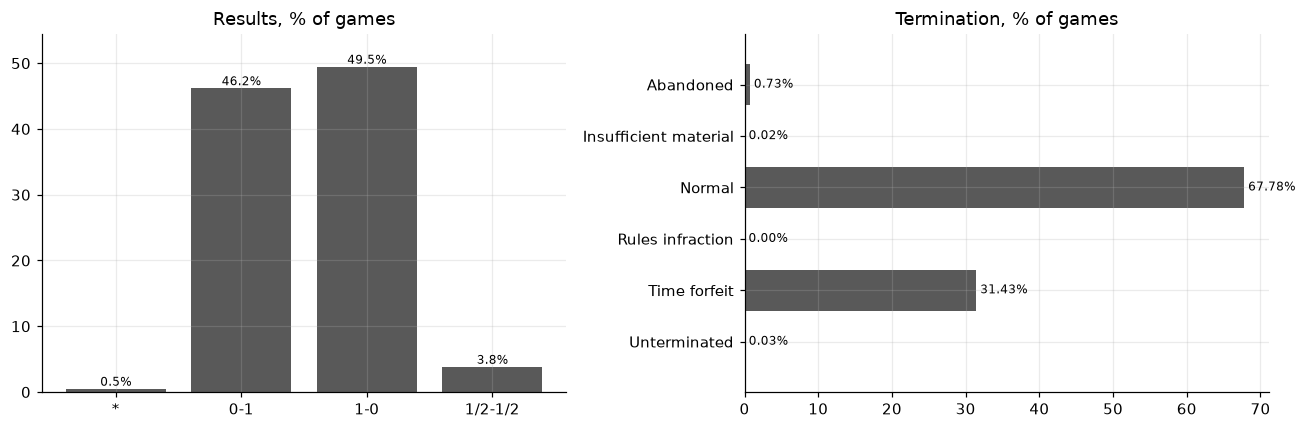

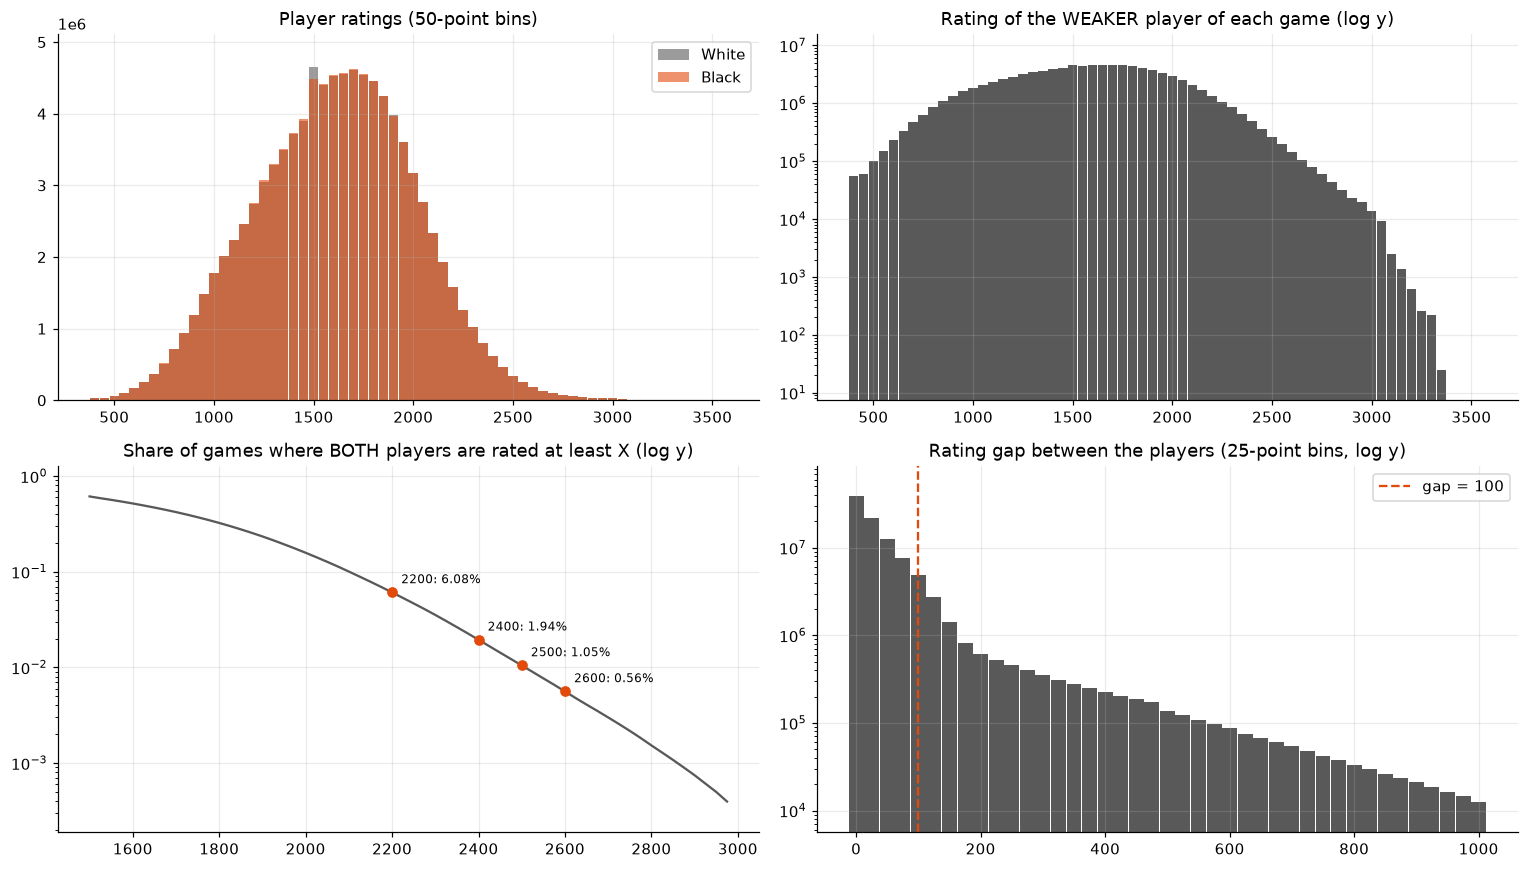

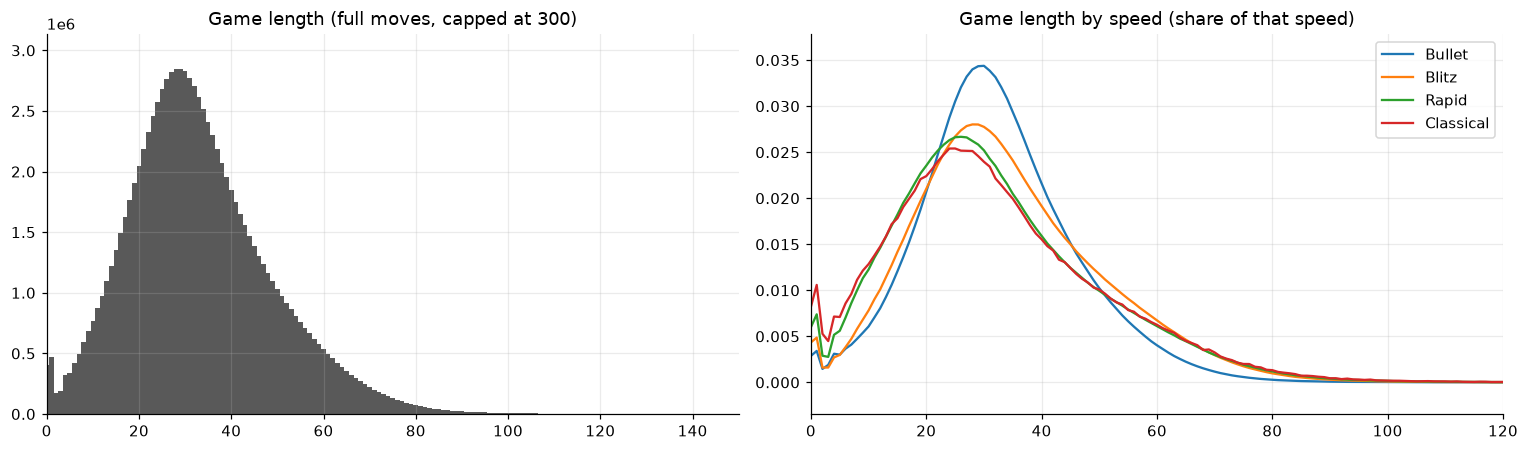

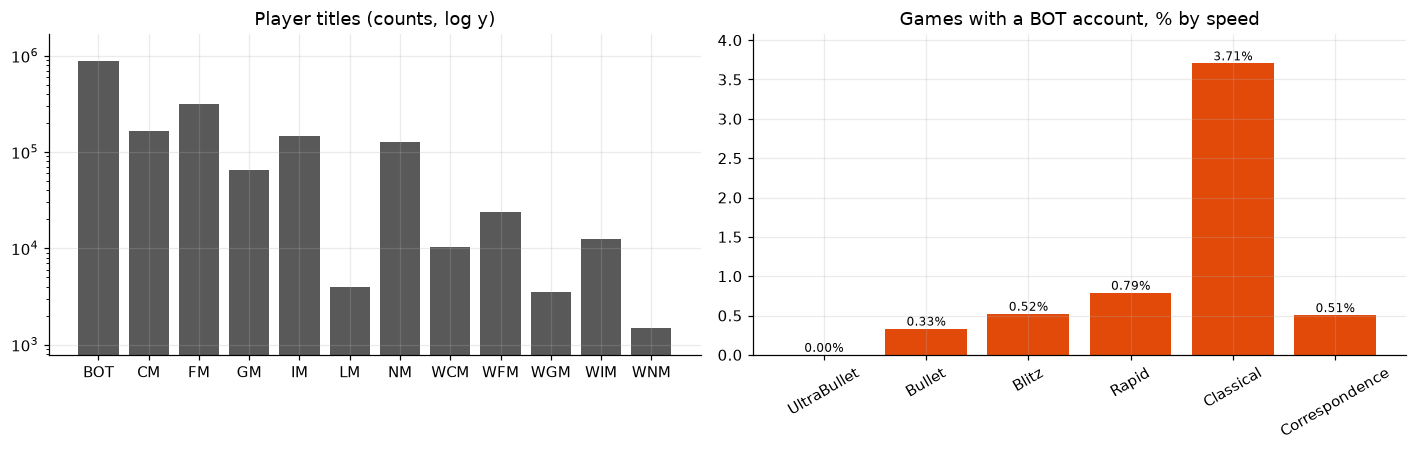

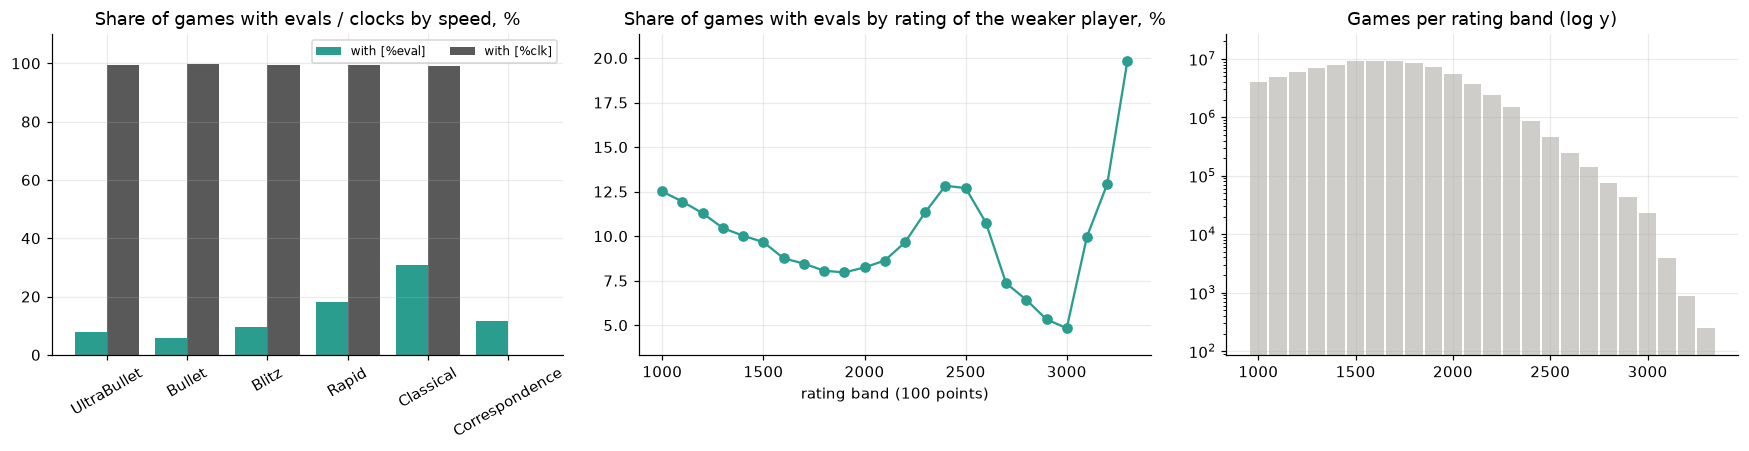

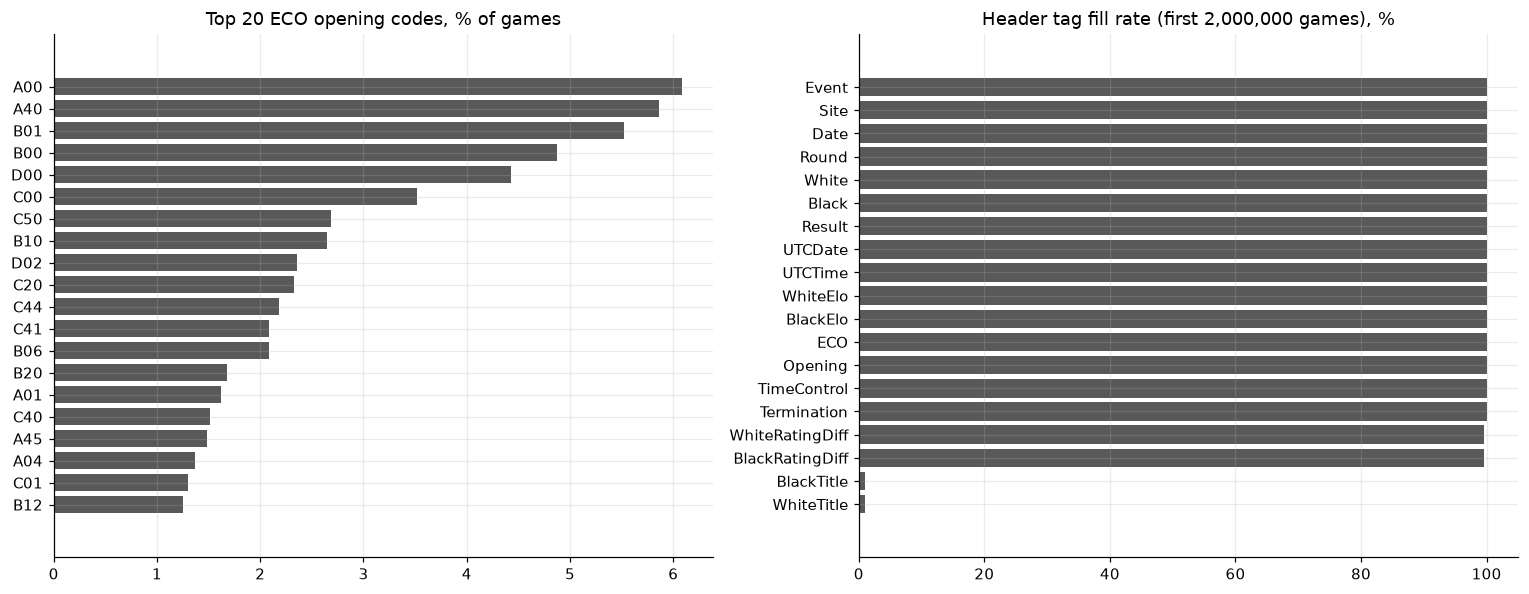

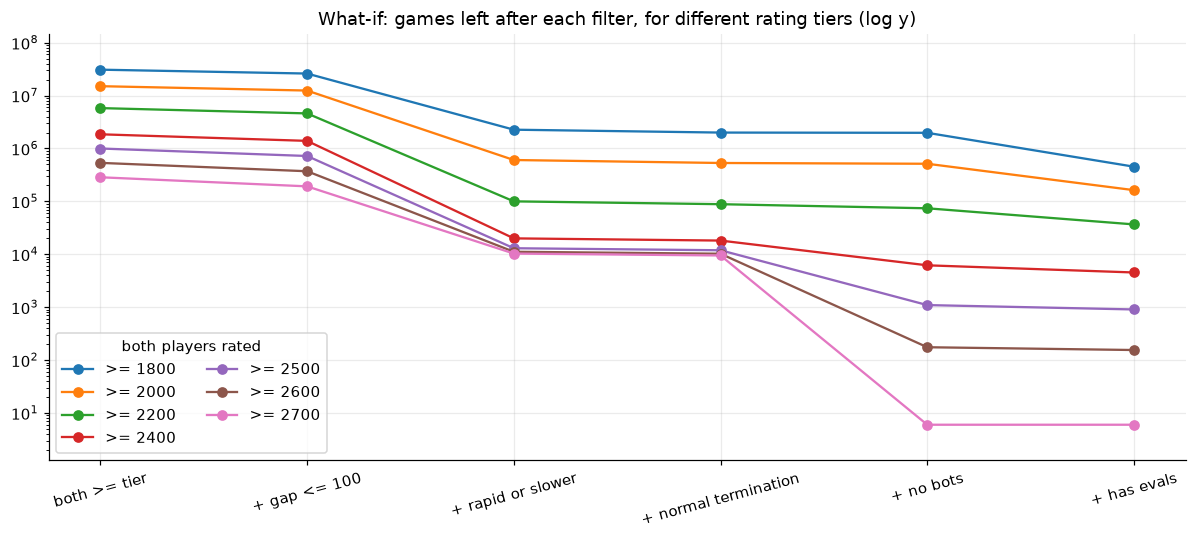

,>= 1800,>= 2000,>= 2200,>= 2400,>= 2500,>= 2600,>= 2700
both >= tier,30862894,15049267,5796478,1853698,998660,534440,285546
+ gap <= 100,26072285,12441089,4601306,1391822,720969,371153,192285
+ rapid or slower,2264688,605053,100095,19986,13012,11159,10312
+ normal termination,1997782,531674,88450,18163,11916,10245,9491
+ no bots,1977124,514042,74035,6187,1096,175,6
+ has evals,452530,162952,36697,4529,906,155,6


In [13]:
COL = {"main": "#595959", "acc": "#E24A0A", "teal": "#2A9D8F", "light": "#CFCDC9"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "font.size": 10, "axes.ymargin": 0.1})
def save(name):
    plt.tight_layout(); plt.savefig(FIGS / f"{name}.png", dpi=200, bbox_inches="tight"); plt.show()
rebin = lambda s, w: s.groupby(s.index // w * w).sum()

# 1. when / what kind of games
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
d = T("games_per_day"); ax[0].plot(d.date.str[-2:], d.games, color=COL["main"], marker="o", ms=3); ax[0].set_title("Games per day of the month"); ax[0].set_xlabel("day"); ax[0].tick_params(axis="x", labelsize=7)
order = [s for s in ["UltraBullet", "Bullet", "Blitz", "Rapid", "Classical", "Correspondence", "Other"] if s in set(speed.speed)]
sp = speed.set_index("speed").reindex(order); ax[1].bar(sp.index, sp.share * 100, color=COL["main"]); ax[1].set_title("Speed category (Event tag), % of games")
for i, v in enumerate(sp.share * 100): ax[1].text(i, v, f"{v:.1f}%", ha="center", va="bottom", fontsize=8)
ax[1].tick_params(axis="x", rotation=30)
t = T("time_controls_top40").head(15); ax[2].barh(t.time_control[::-1], t.share[::-1] * 100, color=COL["main"]); ax[2].set_title("Top 15 time controls (base+increment, s), %")
save("01_days_speed_timecontrol")

# 2. results, terminations
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
r = T("results"); ax[0].bar(r.result, r.share * 100, color=COL["main"]); ax[0].set_title("Results, % of games")
for i, v in enumerate(r.share * 100): ax[0].text(i, v, f"{v:.1f}%", ha="center", va="bottom", fontsize=8)
tm = T("terminations"); ax[1].barh(tm.termination[::-1], tm.share[::-1] * 100, color=COL["main"]); ax[1].set_title("Termination, % of games")
for i, v in enumerate(tm.share[::-1] * 100): ax[1].text(v, i, f" {v:.2f}%", va="center", fontsize=8)
save("02_results_terminations")

# 3. ratings
elo = T("elo_exact").set_index("elo")
fig, ax = plt.subplots(2, 2, figsize=(14, 8))
b = rebin(elo.white, 50); w = rebin(elo.black, 50)
ax[0, 0].bar(b.index, b.values, width=48, alpha=0.6, color=COL["main"], label="White"); ax[0, 0].bar(w.index, w.values, width=48, alpha=0.6, color=COL["acc"], label="Black")
ax[0, 0].set_title("Player ratings (50-point bins)"); ax[0, 0].legend()
m = rebin(elo.min_of_both, 50); ax[0, 1].bar(m.index, m.values, width=48, color=COL["main"]); ax[0, 1].set_yscale("log")
ax[0, 1].set_title("Rating of the WEAKER player of each game (log y)")
xs = np.arange(1500, 3000, 25); tot = elo.min_of_both.sum()
surv = [elo.min_of_both[elo.index >= x].sum() / tot for x in xs]
ax[1, 0].plot(xs, surv, color=COL["main"]); ax[1, 0].set_yscale("log"); ax[1, 0].set_title("Share of games where BOTH players are rated at least X (log y)")
for tt in (2200, 2400, 2500, 2600):
    v = elo.min_of_both[elo.index >= tt].sum() / tot; ax[1, 0].plot(tt, v, "o", color=COL["acc"]); ax[1, 0].annotate(f"{tt}: {v:.2%}", (tt, v), textcoords="offset points", xytext=(6, 6), fontsize=8)
g = T("rating_gap_exact").set_index("gap").games; g = rebin(g.clip(upper=None), 25); g = g[g.index <= 1000]
ax[1, 1].bar(g.index, g.values, width=24, color=COL["main"]); ax[1, 1].set_yscale("log"); ax[1, 1].axvline(100, color=COL["acc"], ls="--", label="gap = 100"); ax[1, 1].legend()
ax[1, 1].set_title("Rating gap between the players (25-point bins, log y)")
save("03_ratings")

# 4. game length
fm = T("full_moves"); fms = T("full_moves_by_speed")
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
ax[0].bar(fm.full_moves, fm.games, width=1, color=COL["main"]); ax[0].set_title("Game length (full moves, capped at 300)"); ax[0].set_xlim(0, 150)
for s_ in [x for x in ["Bullet", "Blitz", "Rapid", "Classical"] if x in set(fms.speed)]:
    q = fms[fms.speed == s_].set_index("full_moves").games; ax[1].plot(q.index, q.values / q.sum(), label=s_)
ax[1].set_xlim(0, 120); ax[1].legend(); ax[1].set_title("Game length by speed (share of that speed)")
save("04_game_length")

# 5. titles and bots
tt = T("titles"); bt = T("bots_by_speed").pivot_table(index="speed", columns="has_bot", values="games", fill_value=0).reindex(order)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].bar(tt.title, tt.games, color=COL["main"]); ax[0].set_yscale("log"); ax[0].set_title("Player titles (counts, log y)")
share_bot = (bt.get(1, 0) / bt.sum(axis=1) * 100); ax[1].bar(share_bot.index, share_bot.values, color=COL["acc"]); ax[1].set_title("Games with a BOT account, % by speed"); ax[1].tick_params(axis="x", rotation=30)
for i, v in enumerate(share_bot.values): ax[1].text(i, v, f"{v:.2f}%", ha="center", va="bottom", fontsize=8)
save("05_titles_bots")

# 6. evals and clocks
evs = T("eval_by_speed").pivot_table(index="speed", columns="has", values="games", fill_value=0).reindex(order)
ck = T("clock_by_speed").pivot_table(index="speed", columns="has", values="games", fill_value=0).reindex(order)
eb = T("eval_by_min_elo_band").pivot_table(index="min_elo_band", columns="has_eval", values="games", fill_value=0)
eb = eb[eb.index >= 1000]
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
x = np.arange(len(order)); ax[0].bar(x - 0.2, evs.get(1, 0) / evs.sum(axis=1) * 100, 0.4, color=COL["teal"], label="with [%eval]")
ax[0].bar(x + 0.2, ck.get(1, 0) / ck.sum(axis=1) * 100, 0.4, color=COL["main"], label="with [%clk]"); ax[0].set_xticks(x); ax[0].set_xticklabels(order, rotation=30); ax[0].set_ylim(0, 110); ax[0].legend(loc="upper right", ncol=2, fontsize=8); ax[0].set_title("Share of games with evals / clocks by speed, %")
ax[1].plot(eb.index, eb.get(1, 0) / eb.sum(axis=1) * 100, marker="o", color=COL["teal"]); ax[1].set_title("Share of games with evals by rating of the weaker player, %"); ax[1].set_xlabel("rating band (100 points)")
ax[2].bar(eb.index, eb.sum(axis=1), width=90, color=COL["light"]); ax[2].set_yscale("log"); ax[2].set_title("Games per rating band (log y)")
save("06_evals_clocks")

# 7. openings, tag fill
e = T("eco_top30").head(20); tf = T("tag_fill_rates")
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
ax[0].barh(e.eco[::-1], e.share[::-1] * 100, color=COL["main"]); ax[0].set_title("Top 20 ECO opening codes, % of games")
ax[1].barh(tf.tag[::-1], tf.share[::-1] * 100, color=COL["main"]); ax[1].set_xlim(0, 105); ax[1].set_title(f"Header tag fill rate (first {min(S['n'], TAG_SAMPLE_GAMES):,} games), %")
save("07_openings_tags")

# 8. what-if funnel for different rating tiers (same order as the thesis pipeline)
co = T("cohort_counts"); stages = ["both >= tier", "+ gap <= 100", "+ rapid or slower", "+ normal termination", "+ no bots", "+ has evals"]
rows = {}
for ti, tv in enumerate(THRESH):
    c = co[co.tier_idx >= ti]; seq = [c.games.sum()]
    for col in ["gap_ok", "rapid_plus", "normal", "no_bot", "has_eval"]:
        c = c[c[col] == 1]; seq.append(c.games.sum())
    rows[f">= {tv}"] = seq
funnel = pd.DataFrame(rows, index=stages)
fig, ax = plt.subplots(figsize=(11, 5))
for colname in funnel.columns: ax.plot(range(len(stages)), funnel[colname].clip(lower=0.5), marker="o", label=colname)
ax.set_yscale("log"); ax.set_xticks(range(len(stages))); ax.set_xticklabels(stages, rotation=15); ax.legend(title="both players rated", ncol=2)
ax.set_title("What-if: games left after each filter, for different rating tiers (log y)")
save("08_funnel_by_rating_tier"); funnel.to_csv(TABLES / "funnel_by_rating_tier.csv"); funnel

## 7. Reproducibility check
Run the whole notebook again (or on another computer with the same file): `file_sha256` and `results_sha256` below must be identical.
Commit `outputs/step0_dataset/<month>/` (manifests, tables, figures) to git, but **not** `data/raw/` (see `.gitignore`).

In [14]:
pm = json.loads((OUT / "profile_manifest.json").read_text()); dm = json.loads(MAN.read_text())
print("file sha256    :", dm["sha256"]); print("file bytes     :", f"{dm['bytes']:,}"); print("results_sha256 :", pm["results_sha256"])
print("games profiled :", f"{pm['games']:,}", "(PARTIAL)" if pm["partial"] else "(whole file)")
print("figures        :", *sorted(p.name for p in FIGS.glob("*.png")), sep="\n  ")

file sha256    : 043906ebfade1bfeb7c00087590fac505370936c028525e4722e2dbd4986ae86
file bytes     : 30,982,323,881
results_sha256 : 4fce373d463737f45fb9d5653d240787518d8dc429c4337a4b97ee71b48bd643
games profiled : 95,395,628 (whole file)
figures        :
  01_days_speed_timecontrol.png
  02_results_terminations.png
  03_ratings.png
  04_game_length.png
  05_titles_bots.png
  06_evals_clocks.png
  07_openings_tags.png
  08_funnel_by_rating_tier.png
